# CDC PTB · три baseline и подбор параметров

## tl;dr

Сравниваются частота исхода, мультиномиальная логистика, LightGBM и CatBoost. Все обучаемые модели видят одинаковые признаки и строки. В проверенном прогоне на validation 2023 CatBoost получил log loss **0,34729**, LightGBM **0,34745**, частотный контроль **0,36053**; разница двух бустингов мала. Выбор параметров и типа модели делает **один** валидационный набор; фолдов нет.

## Контекст и методы

Обучение кандидатов ограничено воспроизводимой случайной подвыборкой 500 000 строк train, валидация — 200 000 строк validation. В финальном ноутбуке выбранная конфигурация переобучается на всех строках train+validation. Ограниченный поиск содержит три значения `C` логистики и по три заранее заданные конфигурации LightGBM/CatBoost; он не доказывает глобальный оптимум. Early stopping использует только validation 2023. Калибровочная часть 2023 и метки 2024 здесь не используются.

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .16})
BLUE, ORANGE, GOLD, SLATE = "#28628A", "#BA6234", "#B78918", "#3B4855"
from src.training.preterm_cdc import run_search

## Результаты · единый критерий выбора

In [4]:
candidates, selected = run_search()
cols = ["id", "family", "iterations", "n", "multiclass_log_loss", "multiclass_brier", "auprc_lt32", "auprc_lt34", "auprc_lt37"]
display(candidates[cols].round(5))
print("Выбранный тип:", selected["champion_family"], "; набор:", selected["best_by_family"][selected["champion_family"]]["candidate"]["id"])

Выбранный тип: catboost ; набор: catboost_medium


,id,family,iterations,n,multiclass_log_loss,multiclass_brier,auprc_lt32,auprc_lt34,auprc_lt37
0,catboost_medium,catboost,558,200000,0.34729,0.15858,0.03455,0.05790,0.17225
1,catboost_deeper,catboost,466,200000,0.34729,0.15858,0.03400,0.05769,0.17222
2,catboost_shallow,catboost,597,200000,0.34738,0.15861,0.03436,0.05756,0.17176
3,lightgbm_small,lightgbm,211,200000,0.34745,0.15863,0.03371,0.05682,0.17108
4,lightgbm_medium,lightgbm,116,200000,0.34747,0.15863,0.03356,0.05681,0.17112
5,lightgbm_flexible,lightgbm,78,200000,0.34755,0.15864,0.03336,0.05655,0.17077
6,logreg_c_5,logreg,0,200000,0.35043,0.15940,0.02913,0.04993,0.15973
7,logreg_c_0p5,logreg,0,200000,0.35043,0.15940,0.02913,0.04993,0.15973
8,logreg_c_0p05,logreg,0,200000,0.35043,0.15940,0.02913,0.04993,0.15973
9,prevalence,prevalence,0,200000,0.36054,0.16258,0.01248,0.02188,0.08738


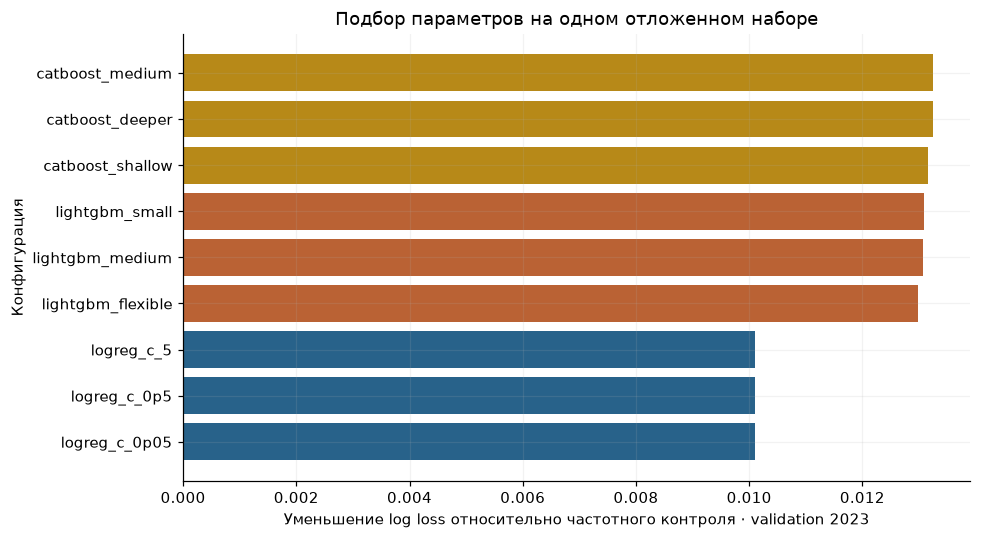

In [5]:
baseline_loss = candidates.loc[candidates.family.eq("prevalence"), "multiclass_log_loss"].iloc[0]
plot = candidates.loc[candidates.family.ne("prevalence")].copy()
plot["gain"] = baseline_loss - plot.multiclass_log_loss
plot = plot.sort_values("gain")
colors = plot.family.map({"logreg": BLUE, "lightgbm": ORANGE, "catboost": GOLD})
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot.id, plot.gain, color=colors)
ax.set(xlabel="Уменьшение log loss относительно частотного контроля · validation 2023", ylabel="Конфигурация", title="Подбор параметров на одном отложенном наборе")
plt.tight_layout(); plt.show()

## Выводы

Метрики validation использованы для выбора, поэтому не являются независимой оценкой победителя. Перестановочная важность и абляции ниже также исследовательские на validation; итоговую проверку переноса даёт 2024. Все исходы объединены в одну модель, так что оценки `<32 ≤ <34 ≤ <37` согласованы.